# Day 68: XGBoost — Boosting Theory & Why It Wins Kaggle

## Objective
- Understand boosting vs bagging
- See gradient boosting fit residuals, step by step
- Train an `XGBClassifier` and read feature importances
- Compare XGBoost with Random Forest on the same data

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import accuracy_score, roc_auc_score, mean_squared_error

from xgboost import XGBClassifier

## Theory
- **Bagging** (Random Forest): many trees train **in parallel**, then vote
- **Boosting**: trees train **one after another**, each fixing the mistakes of the ones before
- **Gradient boosting**: each new tree is fit to the **residuals** (errors) of the ensemble so far
- **XGBoost** = a fast, regularized version of gradient boosting
  - built-in regularization (`reg_lambda`, `reg_alpha`)
  - handles missing values natively
  - much faster than sklearn's older GBM
- `learning_rate` controls how much each new tree is allowed to change the answer

In [2]:
# Load football match data (some values are missing on purpose)
df = pd.read_csv("dataset.csv")
print(df.shape)
print(df.isna().sum()[["possession_pct", "pass_accuracy"]])

(800, 8)
possession_pct    44
pass_accuracy     63
dtype: int64


## Example 1: Boosting by hand (fit the residuals)

In [3]:
# Predict goal difference using 3 complete columns
cols = ["shots_on_target", "fouls", "home_game"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    df[cols], df["goal_diff"], test_size=0.25, random_state=42
)

# Step 0: start with a dumb guess = the average
pred = np.full(len(yr_train), yr_train.mean())
print("Start (average only): MSE =", round(mean_squared_error(yr_train, pred), 3))

# Each new small tree learns the leftover errors
lr = 0.5
for i in range(1, 4):
    residuals = yr_train - pred
    tree = DecisionTreeRegressor(max_depth=2, random_state=42)
    tree.fit(Xr_train, residuals)
    pred = pred + lr * tree.predict(Xr_train)
    print(f"After tree {i}: MSE =", round(mean_squared_error(yr_train, pred), 3))

Start (average only): MSE = 2.873
After tree 1: MSE = 2.177
After tree 2: MSE = 1.934
After tree 3: MSE = 1.822


## Example 2: XGBClassifier

In [4]:
# Classification target: did the team win?
features = ["shots_on_target", "possession_pct", "pass_accuracy", "fouls", "home_game"]
X = df[features]
y = df["won_match"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Note: X_train still contains missing values (NaN)
xgb = XGBClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=3,
    reg_lambda=1.0, random_state=42, eval_metric="logloss"
)
xgb.fit(X_train, y_train)

preds = xgb.predict(X_test)
probs = xgb.predict_proba(X_test)[:, 1]
print("XGBoost accuracy:", round(accuracy_score(y_test, preds), 3))
print("XGBoost AUC:     ", round(roc_auc_score(y_test, probs), 3))

XGBoost accuracy: 0.715
XGBoost AUC:      0.764


## Example 3: Feature importances

home_game          0.366
shots_on_target    0.229
possession_pct     0.207
pass_accuracy      0.106
fouls              0.092
dtype: float32


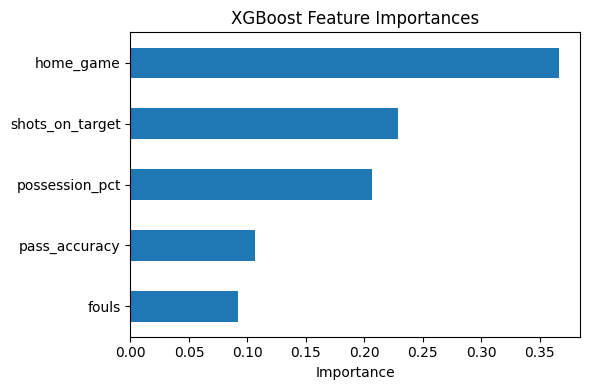

In [5]:
importances = pd.Series(xgb.feature_importances_, index=features)
print(importances.sort_values(ascending=False).round(3))

importances.sort_values().plot(kind="barh", color="#1f77b4", figsize=(6, 4))
plt.xlabel("Importance")
plt.title("XGBoost Feature Importances")
plt.tight_layout()
plt.savefig("images/xgboost_feature_importances.png", dpi=150)
plt.show()

## Example 4: Compare with Random Forest (same split)

In [6]:
# Random Forest needs the gaps filled first (median imputation)
rf = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(n_estimators=100, random_state=42),
)
rf.fit(X_train, y_train)

rf_probs = rf.predict_proba(X_test)[:, 1]
rf_preds = rf.predict(X_test)
print("Random Forest accuracy:", round(accuracy_score(y_test, rf_preds), 3))
print("Random Forest AUC:     ", round(roc_auc_score(y_test, rf_probs), 3))
print("XGBoost accuracy:      ", round(accuracy_score(y_test, preds), 3))
print("XGBoost AUC:           ", round(roc_auc_score(y_test, probs), 3))

Random Forest accuracy: 0.715
Random Forest AUC:      0.747
XGBoost accuracy:       0.715
XGBoost AUC:            0.764


## Example 5: Missing values

In [7]:
# Logistic Regression refuses NaN...
try:
    LogisticRegression(max_iter=1000).fit(X_train, y_train)
except ValueError as e:
    print("LogReg error:", str(e).split("\n")[0])

# ...but XGBoost already trained on the same NaN data above
print("NaN rows in X_train:", int(X_train.isna().any(axis=1).sum()))
print("XGBoost trained fine, AUC =", round(roc_auc_score(y_test, probs), 3))

LogReg error: Input X contains NaN.
NaN rows in X_train: 85
XGBoost trained fine, AUC = 0.764


## Practice Exercise
Train a second `XGBClassifier` with `learning_rate=0.5` and `n_estimators=100`. Does the test AUC go up or down compared with `learning_rate=0.1`?

In [8]:
# Your turn: a much bigger learning rate
fast = XGBClassifier(
    n_estimators=100, learning_rate=0.5, max_depth=3,
    random_state=42, eval_metric="logloss"
)
fast.fit(X_train, y_train)
fast_auc = roc_auc_score(y_test, fast.predict_proba(X_test)[:, 1])
print("lr=0.1 AUC:", round(roc_auc_score(y_test, probs), 3))
print("lr=0.5 AUC:", round(fast_auc, 3))

lr=0.1 AUC: 0.764
lr=0.5 AUC: 0.699


## Mini Challenge
Compare XGBoost with `max_depth=2` and `max_depth=6`. Which depth gives the best test AUC?

In [9]:
# Try a few depths and keep the AUC for each
for depth in [2, 3, 6]:
    m = XGBClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=depth,
        random_state=42, eval_metric="logloss"
    ).fit(X_train, y_train)
    auc_d = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
    print("max_depth", depth, "-> AUC", round(auc_d, 3))

max_depth 2 -> AUC 0.773
max_depth 3 -> AUC 0.764
max_depth 6 -> AUC 0.738


## Summary
- Bagging = parallel trees that vote; boosting = sequential trees that fix errors
- Gradient boosting fits each new tree to the residuals
- XGBoost adds regularization, speed, and native NaN handling
- `learning_rate` and `max_depth` are the first settings to tune
- Always compare against a simpler model, like Random Forest, on the same split